# Bengaluru House Price Prediction

## Problem Statement

Real-estate prices in Bengaluru vary widely based on factors such as location, square footage, number of rooms, amenities, and construction type.  
However, buyers and sellers often struggle to understand whether a listed price is reasonable.

The goal of this project is to **build a data-driven model** that can estimate the price of a house in Bengaluru using available property features.

---

## Project Objectives

- Understand and clean the housing dataset  
- Engineer meaningful features (BHK, price per sqft, etc.)  
- Handle outliers and incorrect/misleading entries  
- Build a reproducible machine-learning pipeline  
- Train a **Multiple Linear Regression** model  
- Evaluate performance using R², Adjusted R², and RMSE  
- Check regression assumptions (residuals, normality, VIF)  
- Interpret results clearly and honestly

> Final outcome: A reasonably accurate and interpretable model that can predict Bengaluru house prices and help understand key price drivers.


In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bengaluru_house_prices.csv")

In [3]:
df = df.copy()

## **Exploratory Data Analysis (EDA)**


In [4]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [5]:
df.shape

(13320, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [7]:
df.isna().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(529)

In [9]:
for column in df.columns:
    print(df[column].value_counts())
    print("*"*20)

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64
********************
availability
Ready To Move    10581
18-Dec             307
18-May             295
18-Apr             271
18-Aug             200
                 ...  
16-Oct               1
17-Jan               1
16-Nov               1
16-Jan               1
14-Jul               1
Name: count, Length: 81, dtype: int64
********************
location
Whitefield                         540
Sarjapur  Road                     399
Electronic City                    302
Kanakpura Road                     273
Thanisandra                        234
                                  ... 
3rd Stage Raja Rajeshwari Nagar      1
Chuchangatta Colony                  1
Electronic City Phase 1,             1
Chikbasavanapura                     1
Abshot Layout                        1
Name: count, Length: 1305, dtype: int64
********************
siz

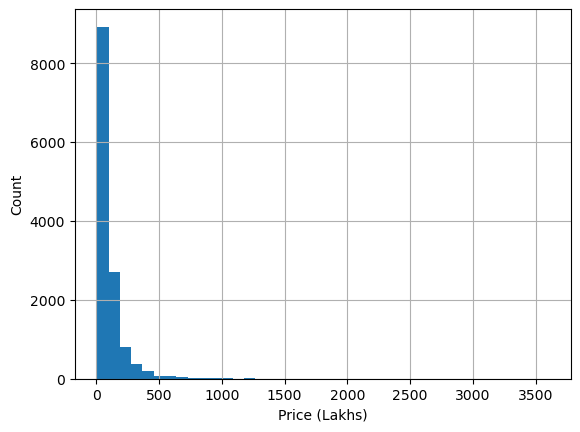

In [10]:
import matplotlib.pyplot as plt

df['price'].hist(bins=40)
plt.xlabel("Price (Lakhs)")
plt.ylabel("Count")
plt.show()

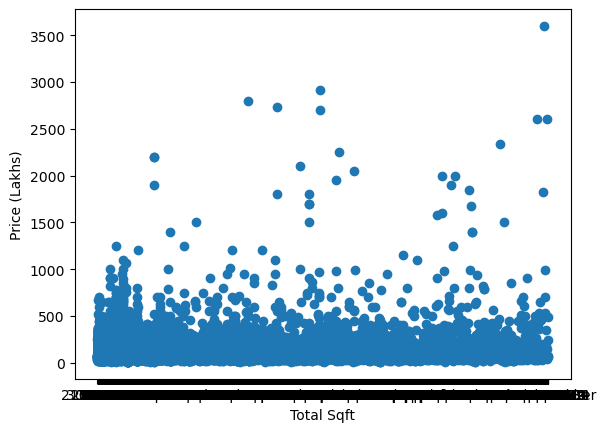

In [11]:
plt.scatter(df['total_sqft'], df['price'])
plt.xlabel("Total Sqft")
plt.ylabel("Price (Lakhs)")
plt.show()

In [12]:
df.groupby('size')['price'].mean().sample(10)

size
5 BHK         425.618644
2 Bedroom      93.563465
5 Bedroom     252.929293
1 RK           28.122308
43 Bedroom    660.000000
3 Bedroom     158.218976
11 BHK        255.000000
27 BHK        230.000000
9 Bedroom     240.847826
10 BHK        342.500000
Name: price, dtype: float64

In [13]:
df.groupby('bath')['price'].mean()

bath
1.0       47.584632
2.0       63.404087
3.0      125.131888
4.0      237.005812
5.0      309.363073
6.0      283.223443
7.0      300.352941
8.0      268.640625
9.0      281.069767
10.0     217.307692
11.0     188.333333
12.0     291.428571
13.0    1341.666667
14.0     500.000000
15.0     125.000000
16.0     520.000000
18.0     200.000000
27.0     230.000000
40.0     660.000000
Name: price, dtype: float64

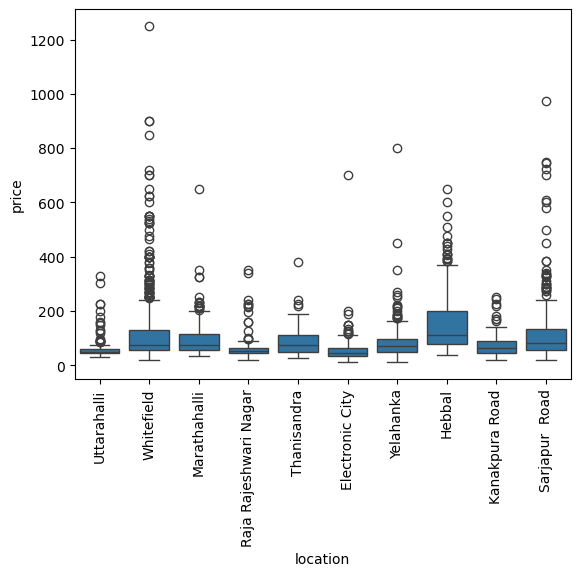

In [14]:
top_locations = df['location'].value_counts().head(10).index
df_top = df[df['location'].isin(top_locations)]

sns.boxplot(x='location', y='price', data=df_top)
plt.xticks(rotation=90)
plt.show()

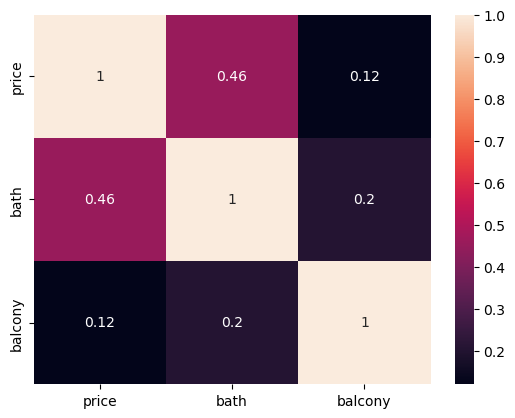

In [15]:
sns.heatmap(df[['price','bath','balcony']].corr(), annot=True)
plt.show()

## **Data Cleaning And Feature Engineering**

In [16]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [17]:
df = df.drop(['society'], axis=1)
df = df.dropna()
df.shape


(12710, 8)

In [18]:
df['location']= df['location'].fillna('Whitefield')

In [19]:
df['size'] = df['size'].fillna('2 BHK')

In [20]:
df['bath'] = df['bath'].fillna(df['bath'].median())

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12710 entries, 0 to 13319
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     12710 non-null  object 
 1   availability  12710 non-null  object 
 2   location      12710 non-null  object 
 3   size          12710 non-null  object 
 4   total_sqft    12710 non-null  object 
 5   bath          12710 non-null  float64
 6   balcony       12710 non-null  float64
 7   price         12710 non-null  float64
dtypes: float64(3), object(5)
memory usage: 893.7+ KB


In [22]:
df["bhk"] = df["size"].str.split().str[0].astype(int)

In [23]:
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,2


In [24]:
df[df.bhk > 10]

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk
459,Super built-up Area,Ready To Move,1 Giri Nagar,11 BHK,5000,9.0,3.0,360.0,11
1718,Super built-up Area,Ready To Move,2Electronic City Phase II,27 BHK,8000,27.0,0.0,230.0,27
1768,Plot Area,Ready To Move,1 Ramamurthy Nagar,11 Bedroom,1200,11.0,0.0,170.0,11
3853,Plot Area,Ready To Move,1 Annasandrapalya,11 Bedroom,1200,6.0,3.0,150.0,11
4684,Plot Area,Ready To Move,Munnekollal,43 Bedroom,2400,40.0,0.0,660.0,43
4916,Super built-up Area,Ready To Move,1Channasandra,14 BHK,1250,15.0,0.0,125.0,14
6533,Plot Area,Ready To Move,Mysore Road,12 Bedroom,2232,6.0,2.0,300.0,12
9935,Super built-up Area,Ready To Move,1Hoysalanagar,13 BHK,5425,13.0,0.0,275.0,13


In [25]:
df['total_sqft'].unique()

array(['1056', '2600', '1440', ..., '1133 - 1384', '774', '4689'],
      dtype=object)

In [26]:
def convertRange(x):

    temp = x.split('-')
    if len(temp) == 2:
        return (float(temp[0]) + float(temp[1]))/2
    try:
        return float(x)
    except:
        return None

In [27]:
df['total_sqft'] = df['total_sqft'].apply(convertRange)

In [28]:
df['price_per_sqft'] = df['price']*100000/df['total_sqft']

In [29]:
df.describe()

,total_sqft,bath,balcony,price,bhk,price_per_sqft
count,12668.000000,12710.000000,12710.000000,12710.000000,12710.000000,1.266800e+04
mean,1511.835167,2.617309,1.584343,106.060778,2.737136,6.876277e+03
std,1162.097276,1.226000,0.817287,131.766089,1.205097,2.263354e+04
min,5.000000,1.000000,0.000000,8.000000,1.000000,2.678298e+02
25%,1100.000000,2.000000,1.000000,49.030000,2.000000,4.242721e+03
50%,1260.000000,2.000000,2.000000,70.000000,3.000000,5.376344e+03
75%,1640.000000,3.000000,2.000000,115.000000,3.000000,7.142857e+03
max,52272.000000,40.000000,3.000000,2912.000000,43.000000,2.300000e+06


In [30]:
df['location'] = df['location'].apply(lambda x: x.strip())
location_counts = df['location'].value_counts()

In [31]:
location_count_less_15 = location_counts[location_counts <= 15]

In [32]:
df['location'] = df['location'].apply(lambda x: "other" if x in location_count_less_15 else x)

In [33]:
df['location'].value_counts()

location
other                    3544
Whitefield                515
Sarjapur  Road            372
Electronic City           302
Kanakpura Road            261
                         ... 
Parappana Agrahara         16
Banashankari Stage VI      16
Kaikondrahalli             16
Banashankari Stage II      16
Banaswadi                  16
Name: count, Length: 174, dtype: int64

In [34]:
(df['total_sqft']/df['bhk']).describe()

count    12668.000000
mean       570.060291
std        380.298999
min          0.714286
25%        473.333333
50%        550.000000
75%        622.500000
max      26136.000000
dtype: float64

In [35]:
df = df[(df['total_sqft']/df['bhk']) >= 300]
df.describe()

,total_sqft,bath,balcony,price,bhk,price_per_sqft
count,12013.000000,12013.000000,12013.000000,12013.000000,12013.000000,12013.000000
mean,1542.315982,2.511779,1.587613,105.003648,2.607259,6206.082347
std,1181.094228,1.006207,0.808867,134.205666,0.922985,3985.518807
min,300.000000,1.000000,0.000000,9.000000,1.000000,267.829813
25%,1107.000000,2.000000,1.000000,48.450000,2.000000,4199.363057
50%,1285.000000,2.000000,2.000000,68.000000,2.000000,5252.525253
75%,1660.000000,3.000000,2.000000,110.000000,3.000000,6823.529412
max,52272.000000,13.000000,3.000000,2912.000000,13.000000,176470.588235


In [36]:
def remove_outliers_sqft_iqr(df):
    df_output = pd.DataFrame()

    for key, subdf in df.groupby('location'):

        Q1 = subdf['price_per_sqft'].quantile(0.25)
        Q3 = subdf['price_per_sqft'].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        filtered_df = subdf[
            (subdf['price_per_sqft'] >= lower_bound) &
            (subdf['price_per_sqft'] <= upper_bound)
        ]

        df_output = pd.concat([df_output, filtered_df], ignore_index=True)

    return df_output


df = remove_outliers_sqft_iqr(df)

In [37]:
df.shape

(11166, 10)

In [38]:
def bhk_outlier_remover_safe(df, variation=0.80, min_count=8):
    exclude_indices = []

    for location, location_df in df.groupby('location'):
        bhk_stats = {}

        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'median': bhk_df['price_per_sqft'].median(),
                'count': len(bhk_df)
            }

        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk - 1)

            if stats and stats['count'] >= min_count:
                threshold = stats['median'] * variation   # allow up to 20% cheaper
                bad = bhk_df[bhk_df['price_per_sqft'] < threshold]
                exclude_indices.extend(list(bad.index))

    return df.drop(exclude_indices, axis="index")

In [39]:
df = bhk_outlier_remover_safe(df)

In [40]:
df.shape

(10133, 10)

In [41]:
df["availability"] = df["availability"].apply(lambda x: "Ready" if x == "Ready To Move" else "Not Ready")

## **Data Preparation**

In [42]:
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft
0,Super built-up Area,Ready,1st Phase JP Nagar,4 BHK,2825.0,4.0,3.0,250.0,4,8849.557522
1,Super built-up Area,Ready,1st Phase JP Nagar,3 BHK,1875.0,3.0,1.0,167.0,3,8906.666667
2,Super built-up Area,Ready,1st Phase JP Nagar,3 BHK,2065.0,4.0,1.0,210.0,3,10169.491525
3,Super built-up Area,Ready,1st Phase JP Nagar,3 BHK,2059.0,3.0,2.0,225.0,3,10927.634774
4,Super built-up Area,Ready,1st Phase JP Nagar,2 BHK,1394.0,2.0,1.0,100.0,2,7173.601148


In [43]:
X = df.drop(['price','price_per_sqft','size','balcony'], axis=1)
y = df['price']

In [44]:
X.head()

,area_type,availability,location,total_sqft,bath,bhk
0,Super built-up Area,Ready,1st Phase JP Nagar,2825.0,4.0,4
1,Super built-up Area,Ready,1st Phase JP Nagar,1875.0,3.0,3
2,Super built-up Area,Ready,1st Phase JP Nagar,2065.0,4.0,3
3,Super built-up Area,Ready,1st Phase JP Nagar,2059.0,3.0,3
4,Super built-up Area,Ready,1st Phase JP Nagar,1394.0,2.0,2


In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## **Model Building**

In [46]:
numeric_features = ['total_sqft', 'bath', 'bhk']
categorical_features = ['location', 'area_type', 'availability']

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('regressor', LinearRegression())
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['location', 'area_type',
                                                   'availability']),
                                                 ('num', 'passthrough',
                                                  ['total_sqft', 'bath',
                                                   'bhk'])])),
                ('regressor', LinearRegression())])

## **Model Evaluation**

In [49]:
y_train_pred = pipeline.predict(X_train)
y_test_pred  = pipeline.predict(X_test)

In [50]:
from sklearn.metrics import r2_score

r2_train = r2_score(y_train, y_train_pred)
r2_test  = r2_score(y_test, y_test_pred)

r2_train, r2_test

(0.7711857077827302, 0.7943958412038572)

In [51]:
n = X_test.shape[0]
p = pipeline.named_steps['preprocess'].transform(X_test).shape[1]

adj_r2_test = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)
adj_r2_test

0.7743477650482203

In [53]:
from sklearn.metrics import mean_squared_error,mean_absolute_error
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
rmse

np.float64(43.42265072680342)

In [54]:
mean_absolute_error(y_test,y_test_pred)

20.64312017666115

## **Assumption Checks**

In [53]:
residuals_test  = pd.Series(y_test - y_test_pred)
residuals_train = pd.Series(y_train - y_train_pred)

## **1.Linearity + Homoscedasticity**

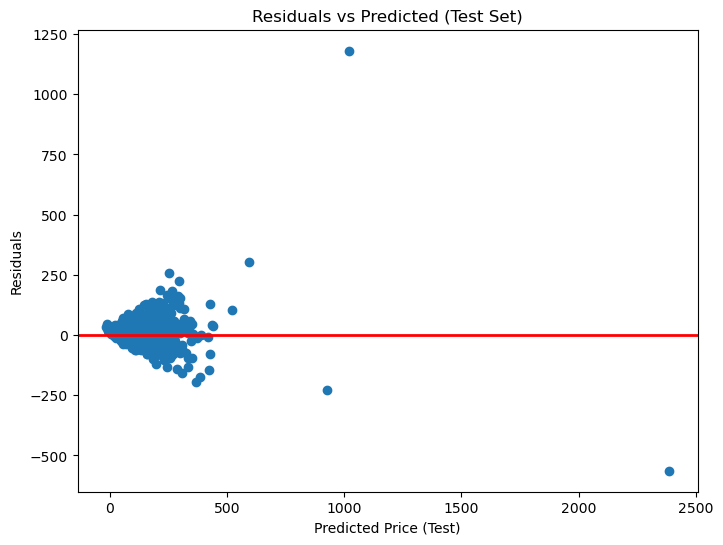

In [54]:
plt.figure(figsize=(8,6))
plt.scatter(y_test_pred, residuals_test) 
plt.axhline(0, color='red', linewidth=2)
plt.xlabel("Predicted Price (Test)")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Test Set)")
plt.show()

Residuals are roughly centered around zero without strong curvature, suggesting the linearity assumption is reasonably satisfied. However, variance increases for higher-priced properties and a few extreme outliers are present, indicating some heteroscedasticity.

## **2.Normality of Residuals**

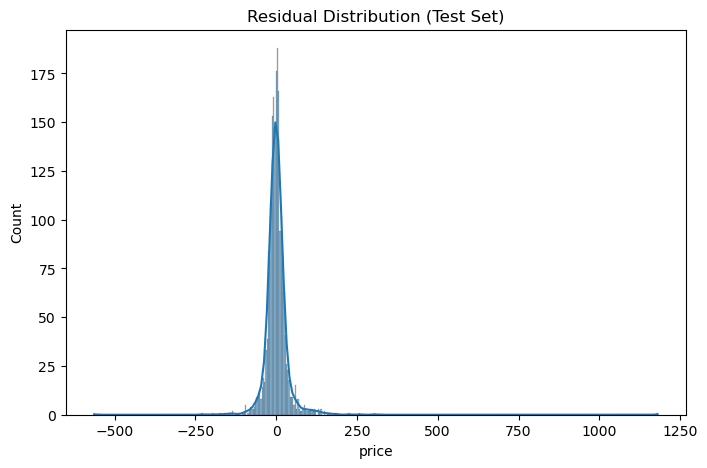

In [55]:
plt.figure(figsize=(8,5))
sns.histplot(residuals_test, kde=True)
plt.title("Residual Distribution (Test Set)")
plt.show()

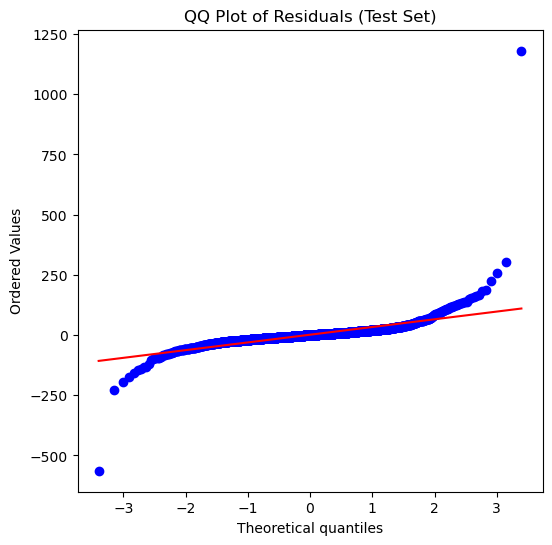

In [56]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(residuals_test, plot=plt)
plt.title("QQ Plot of Residuals (Test Set)")
plt.show()

The histogram and QQ plot show that most residuals are concentrated near zero, but there are heavy tails and a few extreme outliers. This indicates deviations from perfect normality, which is common in real-world price data. Since the goal is prediction rather than statistical inference, the model remains acceptable.

## **Multicollinearity**

In [57]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

numeric_cols = ['total_sqft', 'bhk', 'bath', 'balcony']

X_vif = df[numeric_cols].copy()

# drop rows with missing values
X_vif = X_vif.dropna()

# add intercept
X_vif_const = sm.add_constant(X_vif)

vif_df = pd.DataFrame()
vif_df['feature'] = X_vif_const.columns
vif_df['VIF'] = [
    variance_inflation_factor(X_vif_const.values, i)
    for i in range(X_vif_const.shape[1])
]

vif_df



,feature,VIF
0,const,11.314727
1,total_sqft,1.955280
2,bhk,3.883926
3,bath,4.104966
4,balcony,1.081213


Variance Inflation Factor (VIF) values were computed for the main numeric predictors. All values were below 5, indicating no serious multicollinearity. Therefore, no variables were removed based on VIF analysis.

## Model Evaluation Summary

**Final Model:** Multiple Linear Regression (with Pipeline + ColumnTransformer)

**Performance (Test Set):**

- **R²:** ~0.77  
- **Adjusted R²:** ~0.77  
- **RMSE:** ~₹43 Lakhs  

Train and test scores were close, indicating **good generalization** and minimal overfitting.

---

## Regression Assumption Checks

### 1. Linearity
Residual vs Predicted plot did not show strong curvature.  
A slight increase in spread for higher prices was observed (common in housing data).

 Linearity is reasonably satisfied.

---

### 2. Homoscedasticity (constant variance)
Residual spread increases for expensive properties → mild heteroscedasticity.

 Not perfect, but not severe enough to break the model.

---

### 3. Normality of Residuals
Histogram and QQ plot show residuals centered near zero but with heavy tails.

 Some deviation from normality — acceptable since this is a **prediction problem**, not inference.

---

### 4. Multicollinearity (VIF)
All core numeric predictors had **VIF < 5**, meaning no serious multicollinearity.

 Coefficients are reasonably stable.

---

### 5. Outliers
A few extreme high-value properties remained. They were retained to preserve real-world variation.

---

## Conclusion

The model is:

- interpretable  
- reasonably accurate  
- generalizes well  
- assumptions mostly acceptable for predictive modeling  

Future improvements could include log-transforming price, regularization (Ridge/Lasso), and handling high-priced outliers.
